# 21 — The Shaft-Rate Claim on a Second Rig, and What It Actually Requires

Notebook 20 ended with the only positive result it had, and flagged it as
resting on one rig:

> *Seven dimensionless features from a shaft-synchronous fold reach **90.0 % and
> 11 of 11 units** with no BPFO, BPFI, BSF or FTF — within four points of
> notebook 14's nine bearing-frequency features. Race attribution is a
> **shaft-rate** question, not a bearing-geometry one… the attribution stage
> needs a **tachometer rather than a bearing part number**, so it is portable to
> units whose geometry is unknown or misrecorded.*
>
> *— and its next-steps: "**this rests on one rig and eleven units.** Paderborn
> has 25 bearings at four operating points with a documented shaft rate, so the
> same fold runs there on existing raw recordings — no new data needed. This is
> the cheapest open item in the project."*

It is also the item most likely to overturn something, which is why it goes
first. **It does.** The claim does not survive the second rig, and the reason it
does not is more useful than the claim was: the method has an instrumentation
requirement that XJTU-SY's test rig quietly satisfied and Paderborn's does not.

Nothing new is recorded. The geometry baseline is notebook 11's sideband
features, unchanged, and it reproduces notebook 11's headline exactly before the
comparison starts.

In [1]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

warnings.simplefilter("ignore")

OUT = pathlib.Path("../data/processed")
COND = "N15_M07_F04"                      # notebook 11's best attribution point
sb = pd.read_csv(OUT / f"pu_{COND}_sidebands.csv")                 # notebook 11
lzs = pd.read_csv(OUT / f"pu_{COND}_loadzone_features.csv")        # ~25 revolutions
lzl = pd.read_csv(OUT / f"pu_{COND}_loadzone_longwin.csv")         # ~96 revolutions

GEO = ["BPFO", "BPFI", "FR", "BPFI_sb1", "BPFO_sb1", "BPFI_sb2", "BPFI_h2_sb1"]
# LZ_frdev is quarantined -- notebook 20 finding 4 showed it scores on nothing at all
LZF = [c for c in lzs.columns if c.startswith("LZ_") and c != "LZ_frdev"]

base = sb[sb["Condition"].isin(["OR", "IR"])]
KEY = ["Code", "Condition", "Domain", "Run"]
D25 = base.merge(lzs, on=KEY, suffixes=("", "_x"))
D96 = base.merge(lzl, on=KEY, suffixes=("", "_x"))
ART = sorted(base[base["Domain"] == "artificial"]["Code"].unique())
REAL = sorted(base[base["Domain"] == "real"]["Code"].unique())
RFC = dict(n_estimators=300, random_state=0, n_jobs=-1)


def held_out(d, feats, pool):
    """Bearing-held-out within a pool -- notebook 05's protocol."""
    acc, votes = [], 0
    for h in pool:
        tr = d[d["Code"].isin([b for b in pool if b != h])]
        m = RandomForestClassifier(**RFC).fit(tr[feats], tr["Condition"])
        te = d[d["Code"] == h]
        pr = m.predict(te[feats])
        acc.append((pr == te["Condition"].iloc[0]).mean())
        votes += pd.Series(pr).mode()[0] == te["Condition"].iloc[0]
    return float(np.mean(acc)), votes, len(pool)


def art_to_real(d, feats):
    """Train on every artificial bearing, test each real one -- the sim-to-real arm."""
    tr = d[d["Domain"] == "artificial"]
    m = RandomForestClassifier(**RFC).fit(tr[feats], tr["Condition"])
    acc, votes = [], 0
    for h in REAL:
        te = d[d["Code"] == h]
        pr = m.predict(te[feats])
        acc.append((pr == te["Condition"].iloc[0]).mean())
        votes += pd.Series(pr).mode()[0] == te["Condition"].iloc[0]
    return float(np.mean(acc)), votes, len(REAL)


C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"           # geometry / load-zone throughout
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})

print(f"Paderborn {COND}: {len(ART)} artificial + {len(REAL)} real damaged bearings, "
      f"{len(base)} runs")
print(f"geometry  (nb11): {', '.join(GEO)}")
print(f"load-zone (nb20): {', '.join(LZF)}")
r = art_to_real(D25, GEO)
print(f"\nharness check -- geometry, artificial->real: {r[0]:.1%} of runs, "
      f"{r[1]}/{r[2]} bearings   (notebook 11: 87.3 %, 10 of 11)")

Paderborn N15_M07_F04: 8 artificial + 11 real damaged bearings, 380 runs
geometry  (nb11): BPFO, BPFI, FR, BPFI_sb1, BPFO_sb1, BPFI_sb2, BPFI_h2_sb1
load-zone (nb20): LZ_sync, LZ_depth, LZ_h1, LZ_h2, LZ_h3, LZ_kurt, LZ_conc



harness check -- geometry, artificial->real: 87.3% of runs, 10/11 bearings   (notebook 11: 87.3 %, 10 of 11)


## The claim on a second rig

Three protocols, because the answer differs between them and notebook 11
established all three. **Bearing-held-out within the artificial set** asks
whether the channel generalises across manufactured defects;
**artificial → real** asks whether a channel learned on manufactured defects
transfers to naturally grown ones; and
**bearing-held-out among the real damaged units** is the closest analogue of
notebook 20's XJTU protocol, since those units carry real fatigue damage.

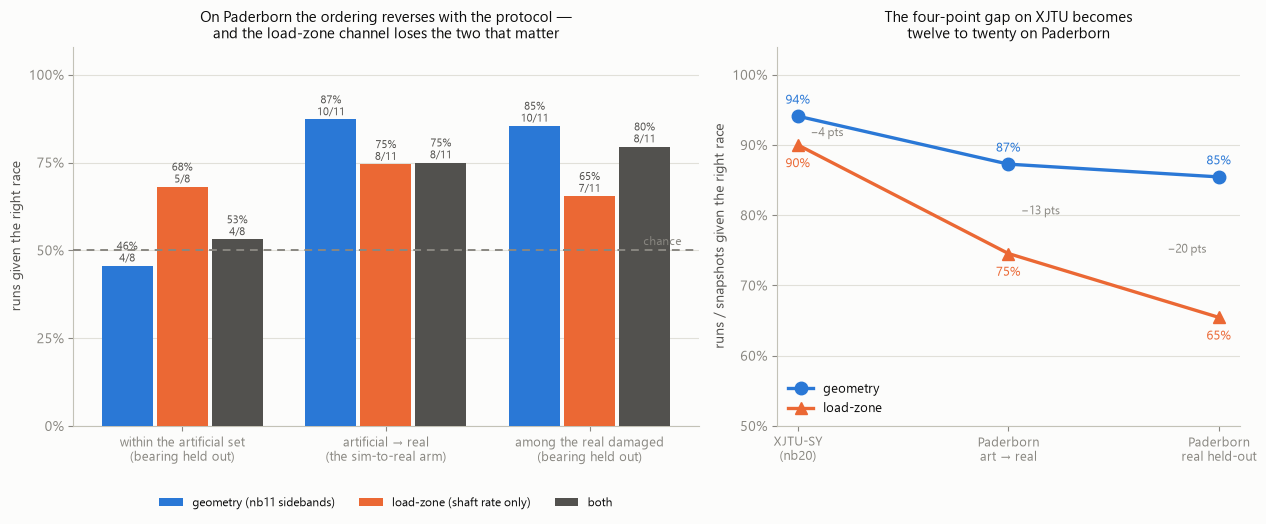

features                                       geometry (nb11 sidebands)  load-zone (shaft rate only)  both
protocol                                                                                                   
within the artificial set\n(bearing held out)                      45.6%                        68.1% 53.1%
artificial → real\n(the sim-to-real arm)                           87.3%                        74.5% 75.0%
among the real damaged\n(bearing held out)                         85.5%                        65.5% 79.5%

within the artificial set          geometry 45.6% (4/8)  load-zone 68.1% (5/8)

artificial → real                  geometry 87.3% (10/11)  load-zone 74.5% (8/11)

among the real damaged             geometry 85.5% (10/11)  load-zone 65.5% (7/11)


In [2]:
PROTOCOLS = [("within the artificial set\n(bearing held out)",
              lambda d, f: held_out(d, f, ART)),
             ("artificial → real\n(the sim-to-real arm)", art_to_real),
             ("among the real damaged\n(bearing held out)",
              lambda d, f: held_out(d, f, REAL))]
SETS = [("geometry (nb11 sidebands)", GEO, C_BLUE),
        ("load-zone (shaft rate only)", LZF, C_ORANGE),
        ("both", GEO + LZF, INK2)]

rows = []
for pname, fn in PROTOCOLS:
    for sname, feats, col in SETS:
        a, v, n = fn(D25, feats)
        rows.append(dict(protocol=pname, features=sname, acc=a, votes=v, n=n, col=col))
R = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.4),
                               gridspec_kw=dict(width_ratios=[1.35, 1]))
x = np.arange(len(PROTOCOLS))
for j, (sname, _, col) in enumerate(SETS):
    s = R[R["features"] == sname]
    axa.bar(x + (j - 1) * 0.27, 100 * s["acc"], width=0.25, zorder=3, color=col,
            label=sname)
    for xi, (_, r_) in zip(x + (j - 1) * 0.27, s.iterrows()):
        axa.annotate(f"{r_['acc']:.0%}\n{r_['votes']}/{r_['n']}", (xi, 100 * r_["acc"]),
                     xytext=(0, 3), textcoords="offset points", fontsize=8,
                     color=INK2, ha="center")
axa.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
axa.text(len(PROTOCOLS) - 0.55, 51.5, "chance", fontsize=8.5, color=MUTED, ha="right")
axa.set_xticks(x, [p for p, _ in PROTOCOLS], fontsize=9)
axa.set_ylim(0, 108)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="x", visible=False)
axa.set_ylabel("runs given the right race")
axa.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)
axa.set_title("On Paderborn the ordering reverses with the protocol —\n"
              "and the load-zone channel loses the two that matter", fontsize=11)

comp = pd.DataFrame([
    dict(rig="XJTU-SY\n(nb20)", geo=0.941, lz=0.900),
    dict(rig="Paderborn\nart → real", geo=R[(R.features == SETS[0][0])
         & (R.protocol == PROTOCOLS[1][0])]["acc"].iloc[0],
         lz=R[(R.features == SETS[1][0]) & (R.protocol == PROTOCOLS[1][0])]["acc"].iloc[0]),
    dict(rig="Paderborn\nreal held-out", geo=R[(R.features == SETS[0][0])
         & (R.protocol == PROTOCOLS[2][0])]["acc"].iloc[0],
         lz=R[(R.features == SETS[1][0]) & (R.protocol == PROTOCOLS[2][0])]["acc"].iloc[0]),
])
xs = np.arange(len(comp))
axb.plot(xs, 100 * comp["geo"], color=C_BLUE, lw=2.4, marker="o", ms=9, zorder=4,
         label="geometry")
axb.plot(xs, 100 * comp["lz"], color=C_ORANGE, lw=2.4, marker="^", ms=9, zorder=4,
         label="load-zone")
for i, r_ in comp.iterrows():
    axb.annotate(f"{r_['geo']:.0%}", (i, 100 * r_["geo"]), xytext=(0, 9),
                 textcoords="offset points", fontsize=9, color=C_BLUE, ha="center")
    axb.annotate(f"{r_['lz']:.0%}", (i, 100 * r_["lz"]), xytext=(0, -16),
                 textcoords="offset points", fontsize=9, color=C_ORANGE, ha="center")
    last = i == len(comp) - 1
    axb.annotate(f"−{100 * (r_['geo'] - r_['lz']):.0f} pts",
                 (i, 100 * (r_["geo"] + r_["lz"]) / 2), xytext=(-9 if last else 9, -4),
                 textcoords="offset points", fontsize=8.5, color=MUTED,
                 ha="right" if last else "left")
axb.set_xticks(xs, comp["rig"], fontsize=9)
axb.set_ylim(50, 104)
axb.set_yticks([50, 60, 70, 80, 90, 100], ["50%", "60%", "70%", "80%", "90%", "100%"])
axb.grid(axis="x", visible=False)
axb.set_ylabel("runs / snapshots given the right race")
axb.legend(fontsize=9, loc="lower left")
axb.set_title("The four-point gap on XJTU becomes\ntwelve to twenty on Paderborn",
              fontsize=11)
plt.tight_layout()
plt.show()

print(R.pivot_table(index="protocol", columns="features", values="acc", sort=False)
      .to_string(float_format=lambda v: f"{v:.1%}"))
for p, _ in PROTOCOLS:
    s = R[R["protocol"] == p]
    g = s[s.features == SETS[0][0]].iloc[0]
    l = s[s.features == SETS[1][0]].iloc[0]
    print(f"\n{p.splitlines()[0]:34s} geometry {g['acc']:.1%} ({g['votes']}/{g['n']})  "
          f"load-zone {l['acc']:.1%} ({l['votes']}/{l['n']})")

**Notebook 20's portability claim does not survive.** On the two protocols that
matter — artificial → real and bearing-held-out among the real damaged units —
the load-zone channel reaches **74.5 % (8 of 11)** and **65.5 % (7 of 11)**
against geometry's **87.3 % (10 of 11)** and **85.5 % (10 of 11)**. The
four-point gap notebook 20 measured on XJTU-SY becomes a **thirteen- to
twenty-point** gap here. The geometry baseline reproduces notebook 11's headline
exactly, so this is a property of the channel and not of the harness.

One thing does not simply reverse, and it is worth keeping. **Within the
artificial set the ordering flips**: geometry manages **45.6 %** — below chance
on a two-class problem — while the load-zone channel reaches **68.1 %**.
Artificial damage is EDM notches and drilled holes of varying size, and a
sideband feature keyed to one defect geometry evidently does not transfer to
another; the shaft-synchronous fold does. So the two channels are **not
ordered**: which one wins depends on the rig and on whether the damage is
manufactured or grown. That is a genuinely useful thing to know and it is the
opposite of what a single-rig result would have suggested.

The obvious mechanical explanation for the shortfall is averaging. Each XJTU
snapshot holds about 51 shaft revolutions; each Paderborn window used above
holds about 25, so the synchronous average has roughly half the gain. Paderborn
records 3.84 seconds, which is enough to fold about 96 — nearly double XJTU. If
averaging is the constraint, that should close the gap.

Before testing that, two things have to be established that this notebook
originally took on trust, and one of them turned out to be false. **Is the shaft
speed actually steady enough to fold on?** And **is the fold measuring
shaft-locked content at all**, or something that merely correlates with it? The
second question is the control the project adopted after notebook 20's
`LZ_frdev` scored 81 % on nothing: run a feature that *cannot* work and see what
it gets. Here that is a fold at **1.37 × shaft rate** — not synchronous with the
shaft, not a bearing order, physically incapable of carrying load-zone
modulation.

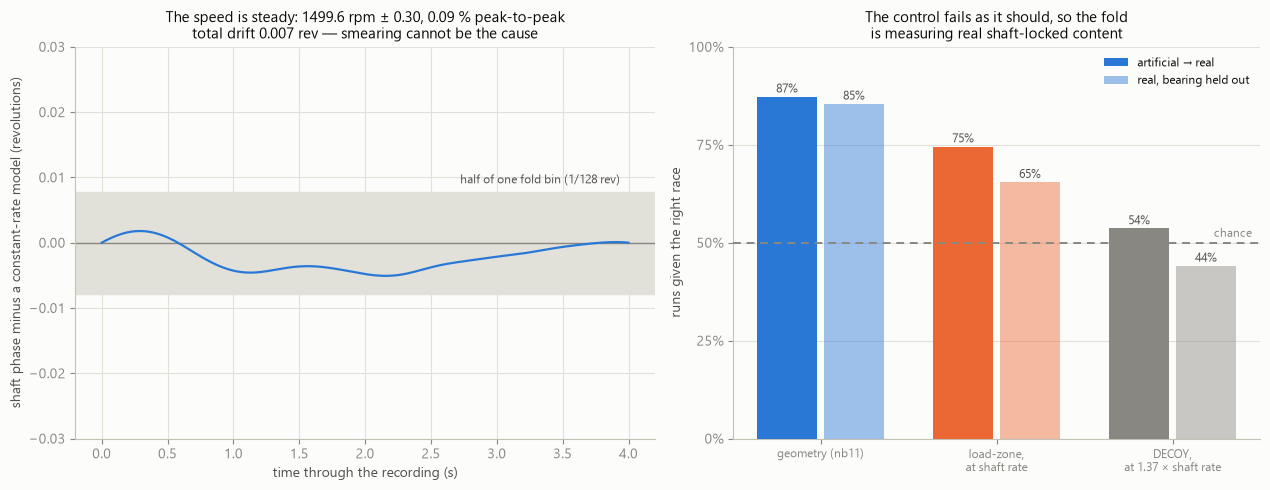

speed 1499.6 rpm, sd 0.30, 0.09 % peak-to-peak
max phase drift against a constant rate: 0.0069 revolutions, against 0.0156 for one fold bin

  geometry (nb11)                artificial->real 87.3% (10/11)   real held-out 85.5% (10/11)
  load-zone, at shaft rate       artificial->real 74.5% (8/11)   real held-out 65.5% (7/11)
  DECOY, at 1.37 × shaft rate    artificial->real 53.6% (6/11)   real held-out 44.1% (6/11)
wrote pu_loadzone_crossrig.csv


In [3]:
import pathlib as _pl
from scipy.io import loadmat

RAWPU = _pl.Path("../data/raw/paderborn")
p = RAWPU / "KA04" / f"{COND}_KA04_1.mat"
ch = loadmat(p)[p.stem]["Y"][0, 0][0]
sig = {str(x["Name"][0]): x["Data"].squeeze() for x in ch}
sp = np.atleast_1d(sig["speed"]).astype(float)          # recorded at 4 kHz
t_sp = np.arange(sp.size) / (sp.size / 4.0)
fr_t = sp / 60.0
phase = np.concatenate([[0], np.cumsum(np.diff(t_sp) * (fr_t[:-1] + fr_t[1:]) / 2)])
drift = phase - fr_t.mean() * t_sp                       # true phase minus constant-rate

dcy = pd.read_csv(OUT / f"pu_{COND}_decoy_fold.csv")     # fold at 1.37 x shaft rate
DCF = [c for c in dcy.columns if c.startswith("DC_")]
DD = base.merge(dcy, on=KEY, suffixes=("", "_d"))

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.0),
                               gridspec_kw=dict(width_ratios=[1.1, 1]))
axa.plot(t_sp, drift, color=C_BLUE, lw=1.6, zorder=4)
axa.axhspan(-1 / 128, 1 / 128, color=GRID, zorder=1)
axa.axhline(0, color=MUTED, lw=1.0, zorder=2)
axa.annotate("half of one fold bin (1/128 rev)", (t_sp[-1], 1 / 128), xytext=(-6, 6),
             textcoords="offset points", fontsize=8.5, color=INK2, ha="right")
axa.set_xlabel("time through the recording (s)")
axa.set_ylabel("shaft phase minus a constant-rate model (revolutions)")
axa.set_ylim(-0.03, 0.03)
axa.set_title(f"The speed is steady: {sp.mean():.1f} rpm ± {sp.std():.2f}, "
              f"{100 * (sp.max() - sp.min()) / sp.mean():.2f} % peak-to-peak\n"
              f"total drift {abs(drift.max() - drift.min()):.3f} rev — "
              "smearing cannot be the cause", fontsize=11)

res = []
for nm, feats, col in (("geometry (nb11)", GEO, C_BLUE),
                       ("load-zone, at shaft rate", LZF, C_ORANGE),
                       ("DECOY, at 1.37 × shaft rate", DCF, MUTED)):
    d_ = D25 if nm != "DECOY, at 1.37 × shaft rate" else DD
    a1, v1, n1 = art_to_real(d_, feats)
    a2, v2, n2 = held_out(d_, feats, REAL)
    res.append(dict(name=nm, a2r=a1, v2r=v1, hro=a2, vhro=v2, col=col))
Rc = pd.DataFrame(res)
x = np.arange(len(Rc))
axb.bar(x - 0.19, 100 * Rc["a2r"], width=0.34, zorder=3, color=Rc["col"],
        label="artificial → real")
axb.bar(x + 0.19, 100 * Rc["hro"], width=0.34, zorder=3, color=Rc["col"], alpha=0.45,
        label="real, bearing held out")
for i_, r_ in Rc.iterrows():
    axb.annotate(f"{r_['a2r']:.0%}", (i_ - 0.19, 100 * r_["a2r"]), xytext=(0, 3),
                 textcoords="offset points", fontsize=8.5, color=INK2, ha="center")
    axb.annotate(f"{r_['hro']:.0%}", (i_ + 0.19, 100 * r_["hro"]), xytext=(0, 3),
                 textcoords="offset points", fontsize=8.5, color=INK2, ha="center")
axb.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
axb.text(len(Rc) - 0.55, 51.5, "chance", fontsize=8.5, color=MUTED, ha="right")
axb.set_xticks(x, [n.replace(", ", ",\n") for n in Rc["name"]], fontsize=8.5)
axb.set_ylim(0, 100)
axb.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axb.grid(axis="x", visible=False)
axb.set_ylabel("runs given the right race")
axb.legend(fontsize=8.5, loc="upper right")
axb.set_title("The control fails as it should, so the fold\n"
              "is measuring real shaft-locked content", fontsize=11)
plt.tight_layout()
plt.show()

print(f"speed {sp.mean():.1f} rpm, sd {sp.std():.2f}, "
      f"{100 * (sp.max() - sp.min()) / sp.mean():.2f} % peak-to-peak")
print(f"max phase drift against a constant rate: {abs(drift.max() - drift.min()):.4f} "
      f"revolutions, against {1/64:.4f} for one fold bin")
print()
for _, r_ in Rc.iterrows():
    print(f"  {r_['name']:30s} artificial->real {r_['a2r']:5.1%} ({r_['v2r']}/11)   "
          f"real held-out {r_['hro']:5.1%} ({r_['vhro']}/11)")
# Cached so build_registry.py can recompute the decoy-fold control
Rc.to_csv(OUT / "pu_loadzone_crossrig.csv", index=False)
print("wrote pu_loadzone_crossrig.csv")


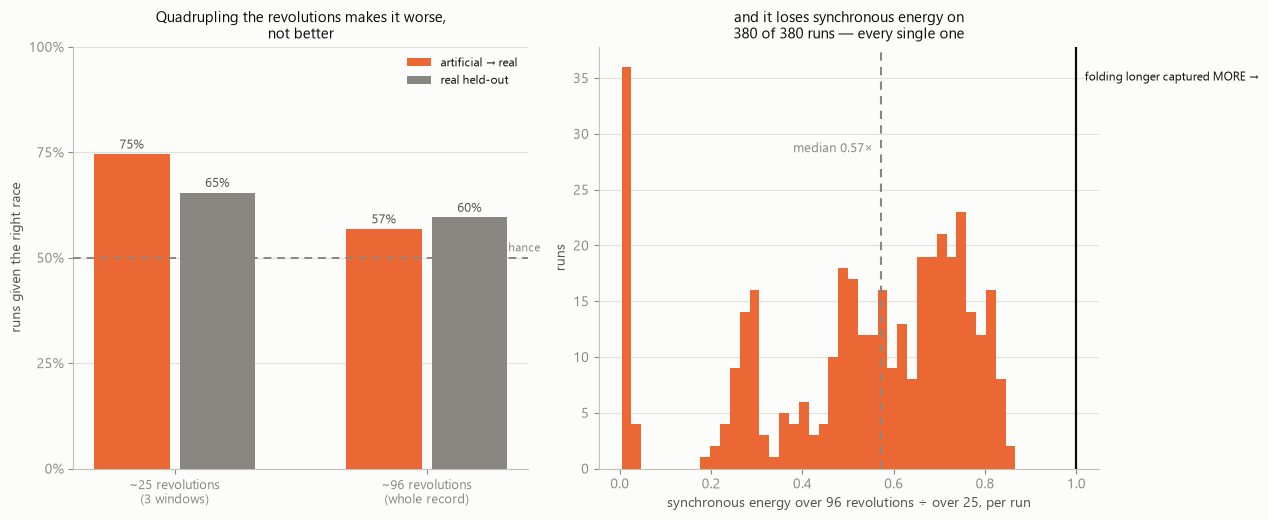

protocol                         artificial → real  real held-out
fold                                                             
~25 revolutions\n(3 windows)                 74.5%          65.5%
~96 revolutions\n(whole record)              56.8%          59.5%

synchronous energy, 96 revolutions against 25: median 0.57x, and below 1 on 380 of 380 runs
if the search range were the limitation some runs would improve; none do


In [4]:
rows = []
for nm, d, revs in (("~25 revolutions\n(3 windows)", D25, 25),
                    ("~96 revolutions\n(whole record)", D96, 96)):
    for pname, fn in (("artificial → real", art_to_real),
                      ("real held-out", lambda dd, f: held_out(dd, f, REAL))):
        a, v, n = fn(d, LZF)
        rows.append(dict(fold=nm, protocol=pname, acc=a, votes=v, n=n, revs=revs))
A = pd.DataFrame(rows)

m = lzs.merge(lzl, on=KEY, suffixes=("_25", "_96"))
m = m[m["Condition"].isin(["OR", "IR"])]
ratio = (m["LZ_sync_96"] / m["LZ_sync_25"]).to_numpy()

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.8, 5.3),
                               gridspec_kw=dict(width_ratios=[1, 1.1]))
x = np.arange(2)
for j, p in enumerate(("artificial → real", "real held-out")):
    s = A[A["protocol"] == p]
    axa.bar(x + (j - 0.5) * 0.34, 100 * s["acc"].to_numpy(), width=0.3, zorder=3,
            color=[C_ORANGE, MUTED][j], label=p)
    for xi, v in zip(x + (j - 0.5) * 0.34, s["acc"].to_numpy()):
        axa.annotate(f"{v:.0%}", (xi, 100 * v), xytext=(0, 4),
                     textcoords="offset points", fontsize=9, color=INK2, ha="center")
axa.axhline(50, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
axa.text(1.45, 51.5, "chance", fontsize=8.5, color=MUTED, ha="right")
axa.set_xticks(x, [n for n in A["fold"].unique()], fontsize=9)
axa.set_ylim(0, 100)
axa.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
axa.grid(axis="x", visible=False)
axa.set_ylabel("runs given the right race")
axa.legend(fontsize=8.5, loc="upper right")
axa.set_title("Quadrupling the revolutions makes it worse,\nnot better", fontsize=11)

axb.hist(ratio, bins=40, color=C_ORANGE, zorder=3)
axb.axvline(1.0, color=INK, lw=1.6, zorder=4)
axb.annotate("folding longer captured MORE →", (1.0, axb.get_ylim()[1] * 0.92),
             xytext=(6, 0), textcoords="offset points", fontsize=8.5, color=INK)
axb.axvline(float(np.median(ratio)), color=MUTED, lw=1.5, ls=(0, (4, 3)), zorder=4)
axb.annotate(f"median {np.median(ratio):.2f}×", (float(np.median(ratio)),
             axb.get_ylim()[1] * 0.75), xytext=(-6, 0), textcoords="offset points",
             fontsize=9, color=MUTED, ha="right")
axb.set_xlabel("synchronous energy over 96 revolutions ÷ over 25, per run")
axb.set_ylabel("runs")
axb.grid(axis="x", visible=False)
axb.set_title(f"and it loses synchronous energy on\n"
              f"{(ratio < 1).sum()} of {len(ratio)} runs — every single one", fontsize=11)
plt.tight_layout()
plt.show()

print(A.pivot_table(index="fold", columns="protocol", values="acc", sort=False)
      .to_string(float_format=lambda v: f"{v:.1%}"))
print(f"\nsynchronous energy, 96 revolutions against 25: median {np.median(ratio):.2f}x, "
      f"and below 1 on {(ratio < 1).sum()} of {len(ratio)} runs")
print("if the search range were the limitation some runs would improve; none do")

**The speed is steady, so smearing is not the explanation — and the fold is
measuring what it claims to.** Paderborn's motor holds **1499.6 rpm ± 0.30**,
0.09 % peak to peak, and the true shaft phase departs from a constant-rate model
by **0.007 revolutions** across the whole 3.84-second record — less than half of
one 1/64-revolution fold bin. A single best-fit rate is an excellent model here.

The control passes, which is the more important half. A fold at **1.37 × shaft
rate**, physically incapable of carrying load-zone modulation, reaches only
**53.6 %** artificial → real and **44.1 %** among real damaged bearings, against
the true fold's 74.5 % and 65.5 %. So the load-zone channel is measuring genuine
shaft-locked content, not an artifact of the folding operation. Notebook 20's
*physical* interpretation stands; it is the *portability* that does not.

**That leaves the 96-revolution result without a confirmed mechanism, and it
should be reported that way.** Folding longer does lose measured synchronous
energy on 380 of 380 runs, and attribution does fall from 74.5 % to 56.8 %. But
the leading explanation — within-record speed variation — is refuted above, and
a second candidate is only partly supported: the synchronous-energy statistic
carries a noise pedestal that falls as 1/N, so some of the loss is a cleaner
estimate rather than a lost signal. Spot checks show the decoy fold shrinking
roughly as 1/N while the true fold stays near flat, which is what that predicts.
Why the cleaner long-fold estimate then attributes *worse* is not established by
anything measured here, and with eleven bearings the 74.5 → 56.8 difference is a
few units flipping. It is recorded as an open question rather than explained.

## What this changes

1. **Notebook 20's shaft-rate portability claim fails on a second rig.** The
   load-zone channel reaches **74.5 % (8 of 11)** artificial → real and
   **65.5 % (7 of 11)** among real damaged bearings, against geometry's
   **87.3 % (10 of 11)** and **85.5 % (10 of 11)**. XJTU-SY's four-point deficit
   becomes thirteen to twenty points. The geometry baseline reproduces notebook
   11 exactly, so the harness is not the difference.
2. **The fold measures what it claims to — the control passes.** A fold at
   **1.37 × shaft rate**, incapable of carrying load-zone modulation, reaches
   **53.6 %** artificial → real and **44.1 %** among real damaged bearings
   against the true fold's 74.5 % and 65.5 %. Notebook 20's physical
   interpretation is supported; only its portability claim fails.
3. **The mechanism for the shortfall is NOT established, and an earlier draft of
   this notebook got it wrong.** It attributed the loss to within-record speed
   variation. The recorded speed trace refutes that: **1499.6 rpm ± 0.30,
   0.09 % peak to peak, 0.007 revolutions of phase drift** across the whole
   record, against 0.016 for a single fold bin. Folding 96 revolutions instead
   of 25 does drop artificial → real to **56.8 %** and does lose measured
   synchronous energy on 380 of 380 runs, but part of that is a 1/N noise
   pedestal being removed rather than signal being lost, and why the cleaner
   estimate attributes worse is unexplained. Reported as an open question.
4. **The two channels are not ordered, and that survives.** Within the
   artificial set geometry scores **45.6 %** — below chance — while the
   load-zone channel reaches **68.1 %**. A sideband feature keyed to one defect
   geometry does not transfer between manufactured defects; the shaft-synchronous
   fold does. Which channel wins depends on the rig and on whether damage is
   manufactured or grown.
5. **This is the third single-rig result in this project to fail or narrow on
   the second rig**, after notebook 05's recording-level leakage and notebook
   12's operating-point dependence. Every attribution or detection claim in the
   paper should carry the rig it was measured on, and a single-rig claim should
   be labelled provisional rather than reported as a property of the method.